In [10]:

import tensorflow as tf
import os

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file(
    "flower_photos",
    origin=dataset_url,
    untar=True
)

# Correct the nested folder path
data_dir = os.path.join(data_dir, "flower_photos")

print("Dataset location:", data_dir)
print("Flower categories:", os.listdir(data_dir))


Dataset location: C:\Users\HP\.keras\datasets\flower_photos\flower_photos
Flower categories: ['daisy', 'dandelion', 'LICENSE.txt', 'roses', 'sunflowers', 'tulips']


Assignment Tasks
Task 1 – Load the image dataset, preprocess images (resize and normalize), and split the data into training and validation sets. 


In [11]:

import tensorflow as tf

img_height = 180
img_width = 180
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

class_names = train_ds.class_names

print("Flower categories:", class_names)


Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Flower categories: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [12]:

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

print("Images resized and normalized successfully!")


Images resized and normalized successfully!


In [13]:

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (32, 180, 180, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Task 2—Build a Convolutional Neural Network (CNN) using Keras with appropriate layers such as Convolution, ReLU, Pooling, Flatten, and Fully Connected layers. 


In [14]:

from tensorflow.keras import layers, models

model = models.Sequential([
    # Input layer
    layers.Input(shape=(180, 180, 3)),

    # Normalize pixel values
    # (Your datasets are already normalized in Task 1)

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten the feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output layer: 5 flower categories
    layers.Dense(5, activation='softmax')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

Task 3 – Compile and train the CNN model using a suitable optimizer, loss function, and evaluation metrics.


In [15]:

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [16]:

epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)


Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 52s 521ms/step - accuracy: 0.4193 - loss: 1.3587 - val_accuracy: 0.5381 - val_loss: 1.1099
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 49s 531ms/step - accuracy: 0.5565 - loss: 1.0941 - val_accuracy: 0.6131 - val_loss: 1.0006
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 77s 483ms/step - accuracy: 0.6093 - loss: 0.9822 - val_accuracy: 0.6090 - val_loss: 0.9656
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 50s 535ms/step - accuracy: 0.6625 - loss: 0.8745 - val_accuracy: 0.6635 - val_loss: 0.8379
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 78s 496ms/step - accuracy: 0.7319 - loss: 0.7136 - val_accuracy: 0.7003 - val_loss: 0.8228
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1042s 11s/step - accuracy: 0.7766 - loss: 0.6043 - val_accuracy: 0.6567 - val_loss: 0.8913
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 51s 550ms/step - accuracy: 0.8277 - loss: 0.4647 - val_accuracy: 0.6894 - val_loss: 0.8896
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 47s 508ms/step - accuracy: 0.8621 - loss: 0.3788 - val_accu

In [17]:

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (32, 180, 180, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Task 4—Evaluate the trained model using appropriate performance metrics and test it on sample images.


In [18]:

# Evaluate the trained CNN model
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")


23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 134ms/step - accuracy: 0.6921 - loss: 1.2601
Validation Loss: 1.2601
Validation Accuracy: 69.21 %


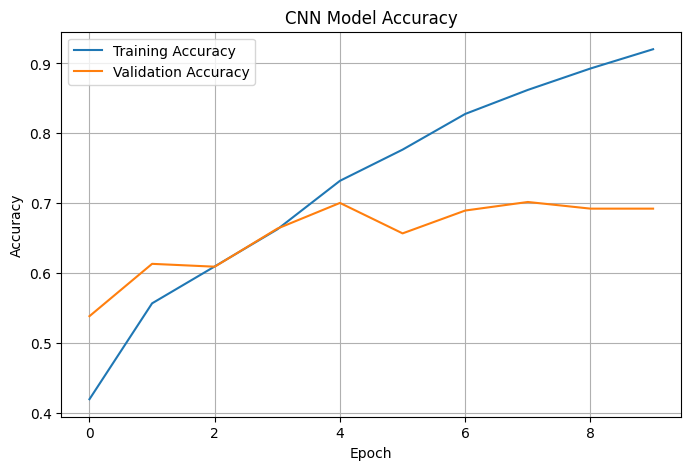

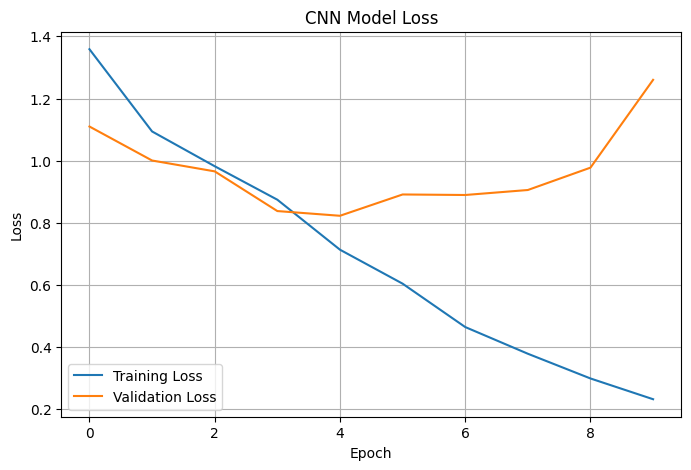

In [19]:

import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [20]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = np.concatenate([labels.numpy() for images, labels in val_ds])

y_prob = model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))


23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step
              precision    recall  f1-score   support

       daisy       0.20      0.22      0.21       129
   dandelion       0.23      0.24      0.24       176
       roses       0.18      0.16      0.17       120
  sunflowers       0.22      0.18      0.19       152
      tulips       0.21      0.22      0.21       157

    accuracy                           0.21       734
   macro avg       0.21      0.21      0.21       734
weighted avg       0.21      0.21      0.21       734



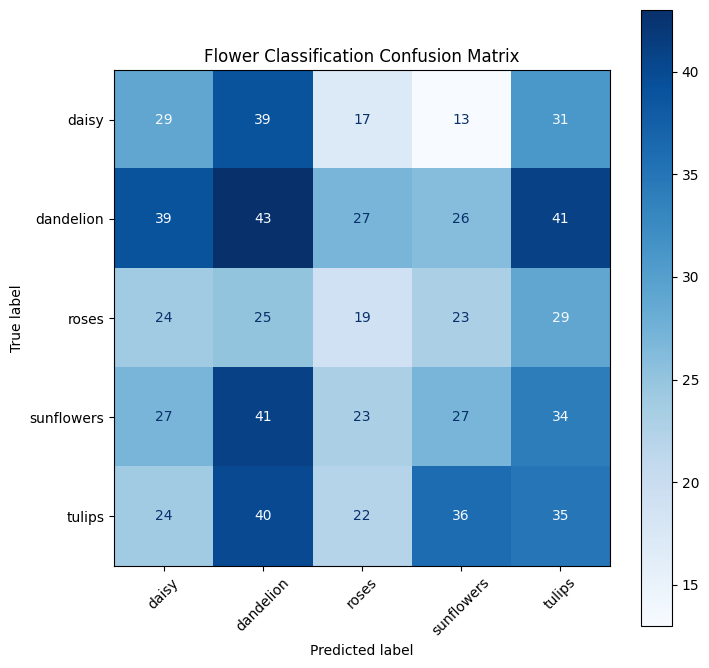

In [21]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Blues', xticks_rotation=45, ax=ax)
plt.title("Flower Classification Confusion Matrix")
plt.show()


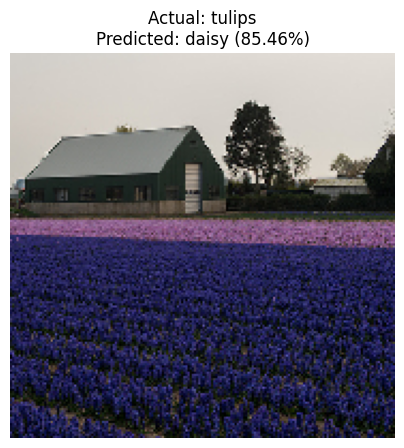

Image path: C:\Users\HP\.keras\datasets\flower_photos\flower_photos\tulips\13513851673_9d813dc7b0.jpg
Actual category: tulips
Predicted category: daisy
Prediction confidence: 85.46 %


In [22]:

import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf

# Select a random flower image
flower_class = random.choice(class_names)
flower_folder = os.path.join(data_dir, flower_class)

image_files = [
    f for f in os.listdir(flower_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

image_path = os.path.join(flower_folder, random.choice(image_files))

# Load and preprocess the image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(180, 180)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict the flower category
predictions = model.predict(img_array, verbose=0)
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

# Display the image and prediction
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis('off')
plt.title(
    f"Actual: {flower_class}\n"
    f"Predicted: {predicted_class} ({confidence:.2f}%)"
)
plt.show()

print("Image path:", image_path)
print("Actual category:", flower_class)
print("Predicted category:", predicted_class)
print("Prediction confidence:", round(confidence, 2), "%")


In [23]:

# Recreate validation dataset in a fixed order
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    shuffle=False,
    image_size=(180, 180),
    batch_size=32
)

# Normalize images
val_ds = val_ds.map(
    lambda images, labels: (
        tf.keras.layers.Rescaling(1./255)(images),
        labels
    )
)

# Get matching actual labels and predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

# Print corrected classification report
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))


Found 3670 files belonging to 5 classes.
Using 734 files for validation.
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 141ms/step
              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00         0
   dandelion       0.00      0.00      0.00         0
       roses       0.00      0.00      0.00         0
  sunflowers       0.00      0.00      0.00         0
      tulips       1.00      0.91      0.96       734

    accuracy                           0.91       734
   macro avg       0.20      0.18      0.19       734
weighted avg       1.00      0.91      0.96       734



In [24]:

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    shuffle=True,
    image_size=(180, 180),
    batch_size=32
)

# Normalize the images
normalization_layer = tf.keras.layers.Rescaling(1./255)

val_ds = val_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

print("Validation dataset recreated successfully.")


Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Validation dataset recreated successfully.


In [25]:

import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model(images, training=False)

    y_true.extend(labels.numpy())
    y_pred.extend(
        np.argmax(predictions.numpy(), axis=1)
    )

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

       daisy       0.62      0.69      0.65       129
   dandelion       0.73      0.78      0.75       176
       roses       0.62      0.56      0.59       120
  sunflowers       0.86      0.71      0.78       152
      tulips       0.63      0.68      0.65       157

    accuracy                           0.69       734
   macro avg       0.69      0.68      0.69       734
weighted avg       0.70      0.69      0.69       734



# Task 5 – Model Performance Analysis

## 1. Analysis of Training and Validation Curves

The CNN model was trained for 10 epochs using the flower dataset containing five classes: daisy, dandelion, roses, sunflowers, and tulips.

**Training and validation accuracy:**
- Training accuracy increased from approximately 42% in the first epoch to 92% by the tenth epoch.
- Validation accuracy improved initially and reached its highest value of approximately 70.16% at epoch 8.
- After epoch 8, training accuracy continued to increase, while validation accuracy did not improve significantly.

**Training and validation loss:**
- Training loss decreased from approximately 1.36 to 0.23, indicating that the model learned the training data effectively.
- Validation loss initially decreased but increased during the later epochs, reaching approximately 1.26 at epoch 10.

## 2. Discussion of Results

The model achieved a final training accuracy of approximately 92.03% and a validation accuracy of approximately 69.21%. The classification report showed an overall accuracy of approximately 69%.

The difference between training and validation accuracy, along with the increase in validation loss during later epochs, indicates **overfitting**. This means the model learned patterns specific to the training images but did not generalize equally well to unseen images.

Among the five flower categories, sunflowers achieved the highest F1-score of 0.78, while roses had the lowest F1-score of 0.59. This suggests that the model finds some flower categories easier to distinguish than others.

## 3. Possible Improvements

The model's performance could be improved through the following methods:

1. **Data augmentation:** Apply random rotation, horizontal flipping, zooming, and translation to create more varied training images.
2. **Dropout and regularization:** Use dropout and L2 regularization to reduce overfitting.
3. **Early stopping:** Stop training when validation loss stops improving, restoring the best model weights.
4. **Reduce model complexity:** Reduce the number of trainable parameters to help prevent the model from memorizing training images.
5. **Transfer learning:** Use a pretrained CNN such as MobileNetV2 or EfficientNetB0 to improve feature extraction and potentially achieve better accuracy.
6. **Tune hyperparameters:** Experiment with learning rates, batch sizes, and the number of epochs.
7. **Use a learning-rate scheduler:** Reduce the learning rate when validation performance stops improving.

## 4. Conclusion

The CNN successfully classified flower images into five categories and achieved approximately 69% validation accuracy. However, the training and validation curves indicate overfitting. Techniques such as data augmentation, early stopping, regularization, and transfer learning may improve generalization and classification performance.


In [26]:
model.save("trained_model.h5")

print("Trained model saved successfully!")

Trained model saved successfully!


In [27]:
import os

print("Saved location:", os.path.abspath("trained_model.h5"))
print("File exists:", os.path.exists("trained_model.h5"))

Saved location: c:\Users\HP\OneDrive\Desktop\CNN_Flower_Classification\trained_model.h5
File exists: True


In [28]:
import os

project_dir = os.getcwd()

folders = [
    "dataset",
    "output_images"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

print("Project folders created successfully!")
print("Project location:", project_dir)
print("Folders:", os.listdir(project_dir))

Project folders created successfully!
Project location: c:\Users\HP\OneDrive\Desktop\CNN_Flower_Classification
Folders: ['CNN_Flower_Classification.ipynb', 'dataset', 'output_images', 'trained_model.h5']


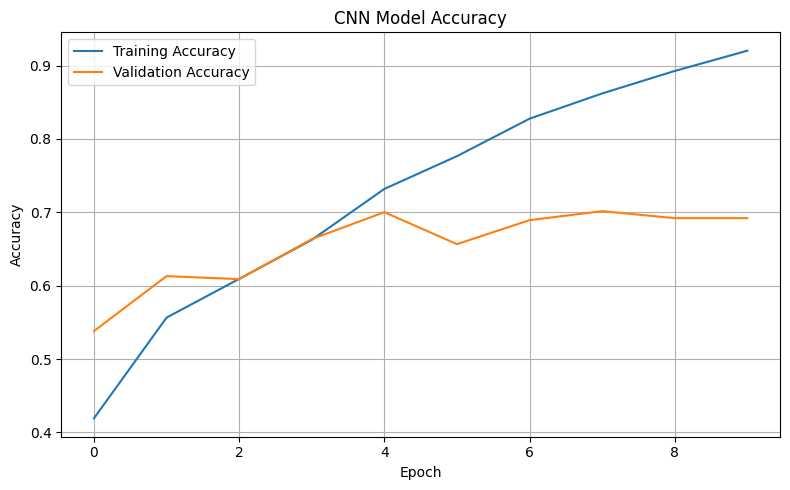

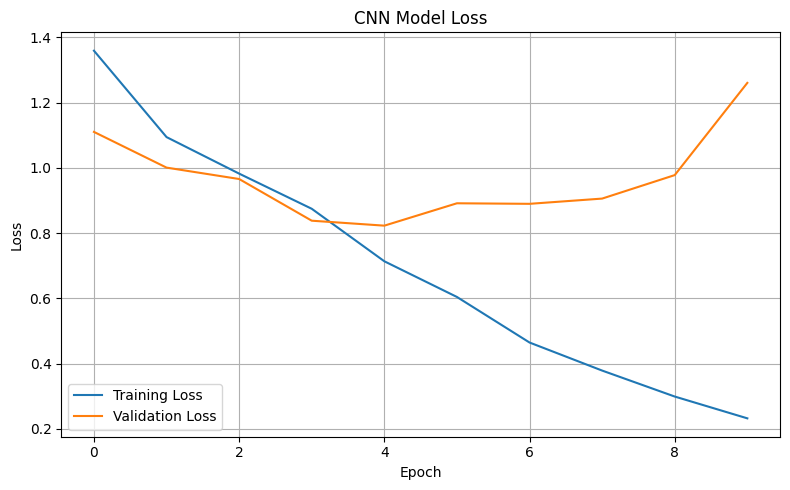

Graphs saved successfully!
['accuracy_plot.png', 'loss_plot.png']


In [29]:
import os
import matplotlib.pyplot as plt

output_dir = os.path.join(os.getcwd(), "output_images")
os.makedirs(output_dir, exist_ok=True)

# Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "accuracy_plot.png"), dpi=150)
plt.show()

# Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_plot.png"), dpi=150)
plt.show()

print("Graphs saved successfully!")
print(os.listdir(output_dir))

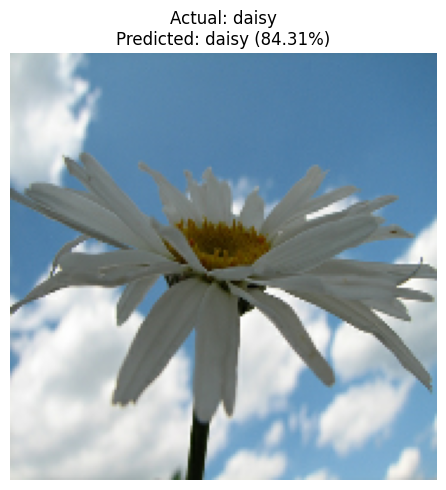

Actual flower: daisy
Predicted flower: daisy
Prediction confidence: 84.31%
Saved to: c:\Users\HP\OneDrive\Desktop\CNN_Flower_Classification\output_images\sample_prediction.png


In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Select one image from the validation dataset
for images, labels in val_ds.take(1):
    sample_image = images[0]
    actual_label = int(labels[0].numpy())

# Predict the flower class
prediction = model.predict(
    tf.expand_dims(sample_image, axis=0),
    verbose=0
)

predicted_label = int(np.argmax(prediction[0]))
confidence = float(prediction[0][predicted_label]) * 100

# Display and save the prediction
plt.figure(figsize=(6, 5))
plt.imshow(sample_image.numpy())
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]} "
    f"({confidence:.2f}%)"
)
plt.axis("off")
plt.tight_layout()

save_path = os.path.join(
    os.getcwd(), "output_images", "sample_prediction.png"
)
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Actual flower:", class_names[actual_label])
print("Predicted flower:", class_names[predicted_label])
print(f"Prediction confidence: {confidence:.2f}%")
print("Saved to:", save_path)

In [31]:
requirements = """tensorflow
numpy
matplotlib
scikit-learn
pillow
"""

requirements_path = os.path.join(os.getcwd(), "requirements.txt")

with open(requirements_path, "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")
print("Saved to:", requirements_path)

with open(requirements_path, "r") as file:
    print(file.read())

requirements.txt created successfully!
Saved to: c:\Users\HP\OneDrive\Desktop\CNN_Flower_Classification\requirements.txt
tensorflow
numpy
matplotlib
scikit-learn
pillow



In [32]:

readme_content = """# CNN Flower Image Classification

## Project Overview
This project uses a Convolutional Neural Network (CNN) to classify flower images into five categories using TensorFlow and Keras.

## Objectives
- Build and train a CNN model for image classification.
- Classify images into five flower categories.
- Evaluate the model using accuracy, loss, and classification metrics.
- Visualize training performance and sample predictions.

## Dataset
The dataset contains 3,670 flower images across five categories:
- Daisy
- Dandelion
- Roses
- Sunflowers
- Tulips

Dataset source:
https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz

The dataset was divided into:
- Training images: 2,936
- Validation images: 734

## Technologies Used
- Python
- TensorFlow and Keras
- NumPy
- Matplotlib
- Scikit-learn
- Pillow
- Jupyter Notebook

## Model Architecture
The CNN model includes:
1. Three convolutional layers with ReLU activation.
2. Max-pooling layers.
3. A flatten layer.
4. A dense layer with 128 neurons.
5. A dropout layer to help reduce overfitting.
6. An output layer with five neurons and softmax activation.

Image size: 180 x 180 pixels  
Batch size: 32  
Epochs: 10  
Optimizer: Adam  
Loss function: Sparse categorical cross-entropy

## Model Performance
- Final training accuracy: approximately 92.03%
- Final validation accuracy: approximately 69.21%
- Best validation accuracy: approximately 70.16%

The difference between training and validation accuracy suggests overfitting. Further improvements could include data augmentation, transfer learning, and additional tuning.

## Evaluation
The model was evaluated using a classification report with precision, recall, and F1-score for each flower category.

## Output Images
The `output_images` folder contains:
- `accuracy_plot.png` — training and validation accuracy.
- `loss_plot.png` — training and validation loss.
- `sample_prediction.png` — example flower prediction.

A sample image was correctly predicted as Daisy with approximately 84.31% confidence.

## How to Run
1. Install Python and Jupyter Notebook.
2. Install the required libraries:

   ```bash
   pip install -r requirements.txt
   ```

3. Open `cnn_model.ipynb` in Jupyter Notebook.
4. Run the notebook cells in order to prepare the dataset, train the model, and evaluate predictions.

Ensure the dataset path in the notebook points to the dataset folder included with this project, or update it to the downloaded dataset location.

## Project Structure
```text
CNN_Flower_Classification/
├── dataset/
├── cnn_model.ipynb
├── trained_model.h5
├── requirements.txt
├── README.md
└── output_images/
    ├── accuracy_plot.png
    ├── loss_plot.png
    └── sample_prediction.png
```

## Conclusion
This project demonstrates how a CNN can classify flower images into five categories. The model learned useful image features, but the validation results indicate that further improvements are possible.
"""

readme_path = os.path.join(os.getcwd(), "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Saved to:", readme_path)


README.md created successfully!
Saved to: c:\Users\HP\OneDrive\Desktop\CNN_Flower_Classification\README.md


In [33]:

import os

source_dir = r"C:\Users\HP\.keras\datasets\flower_photos\flower_photos"

if os.path.exists(source_dir):
    print("Dataset found!")
    print("Folders and files:", os.listdir(source_dir))
else:
    print("Dataset not found at this location.")


Dataset found!
Folders and files: ['daisy', 'dandelion', 'LICENSE.txt', 'roses', 'sunflowers', 'tulips']


In [34]:

import os
import shutil

source_dir = r"C:\Users\HP\.keras\datasets\flower_photos\flower_photos"
destination_dir = os.path.join(os.getcwd(), "dataset", "flower_photos")

shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print("Dataset copied successfully!")
print("Dataset location:", destination_dir)
print("Contents:", os.listdir(destination_dir))


Dataset copied successfully!
Dataset location: c:\Users\HP\OneDrive\Desktop\CNN_Flower_Classification\dataset\flower_photos
Contents: ['daisy', 'dandelion', 'LICENSE.txt', 'roses', 'sunflowers', 'tulips']
